# BÁO CÁO PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA) CHUYÊN SÂU
## BỘ DỮ LIỆU GIAN LẬN THANH TOÁN IEEE-CIS FRAUD DETECTION
> **Tác giả:** Đề tài Khóa luận Tốt nghiệp - Cổng thanh toán phân loại rủi ro Conformal (FinTech IS)  
> **Nguồn dữ liệu:** Vesta Corporation & IEEE Computational Intelligence Society  
> **Mục tiêu:** Khám phá cấu trúc dữ liệu, giải mã các đặc trưng ẩn danh (C, D, M, V), chứng minh hiện tượng mất cân bằng nhãn, trôi dạt thời gian (Concept Drift) và hiện thực hóa kỹ nghệ định danh khách hàng Magic UID.


### 1. Thiết lập Môi trường & Nạp Thư viện

In [1]:
import os
import time
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

# Cau hinh phong cach ve do thi chuan khoa hoc
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Tu dong dinh vi thu muc goc du an du chay o bat ky dau
PROJECT_ROOT = os.path.abspath(os.getcwd())
if not os.path.exists(os.path.join(PROJECT_ROOT, 'data', 'raw')):
    PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))

RAW_DATA_DIR = os.path.join(PROJECT_ROOT, 'data', 'raw')
PROCESSED_DATA_DIR = os.path.join(PROJECT_ROOT, 'data', 'processed')
FIGURES_DIR = os.path.join(PROJECT_ROOT, 'reports', 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(PROCESSED_DATA_DIR, exist_ok=True)

print(f"Thu muc goc du an: {PROJECT_ROOT}")
print(f"Thu muc du lieu tho: {RAW_DATA_DIR}")
print("Môi trường sẵn sàng! Đã nạp thành công Polars, Pandas, Matplotlib và Seaborn.")


Thu muc goc du an: C:\Users\PC\Documents\Git\EDA-chuyen
Thu muc du lieu tho: C:\Users\PC\Documents\Git\EDA-chuyen\data\raw
Môi trường sẵn sàng! Đã nạp thành công Polars, Pandas, Matplotlib và Seaborn.


### 2. Nạp Dữ liệu Tốc độ cao với Polars & Đánh giá Cấu trúc Bảng
Do kích thước file `train_transaction.csv` lên tới ~683 MB và chứa gần 400 cột, chúng ta sử dụng thư viện **Polars** (viết bằng Rust) để đọc toàn bộ dữ liệu chỉ trong vài giây và tối ưu hóa bộ nhớ RAM.


In [2]:
t0 = time.time()
tx_path = os.path.join(RAW_DATA_DIR, 'train_transaction.csv')
id_path = os.path.join(RAW_DATA_DIR, 'train_identity.csv')

# Doc du lieu bang Polars
df_tx = pl.read_csv(tx_path, infer_schema_length=10000)
df_id = pl.read_csv(id_path, infer_schema_length=10000)
load_time = time.time() - t0

print(f"-> Thoi gian doc toan bo du lieu bang Polars: {load_time:.2f} giay")
print(f"-> Kich thuoc train_transaction: {df_tx.shape[0]:,} dong x {df_tx.shape[1]} cot")
print(f"-> Kich thuoc train_identity:    {df_id.shape[0]:,} dong x {df_id.shape[1]} cot")


-> Thoi gian doc toan bo du lieu bang Polars: 3.96 giay
-> Kich thuoc train_transaction: 590,540 dong x 394 cot
-> Kich thuoc train_identity:    144,233 dong x 41 cot


### 3. Phân tích Nhãn Mục tiêu & Mất Cân Bằng Dữ Liệu (Class Imbalance)
Trong các hệ thống thanh toán thực tế, tỷ lệ gian lận luôn chiếm một tỷ lệ rất nhỏ (thường dưới 5%). Hãy cùng đo đạc tỷ lệ chính xác của bộ dữ liệu này.


Thống kê chi tiết nhãn mục tiêu:
               Nhan   count     TyLe_%
0    Hợp lệ (Legit)  569877  96.500999
1  Gian lận (Fraud)   20663   3.499001


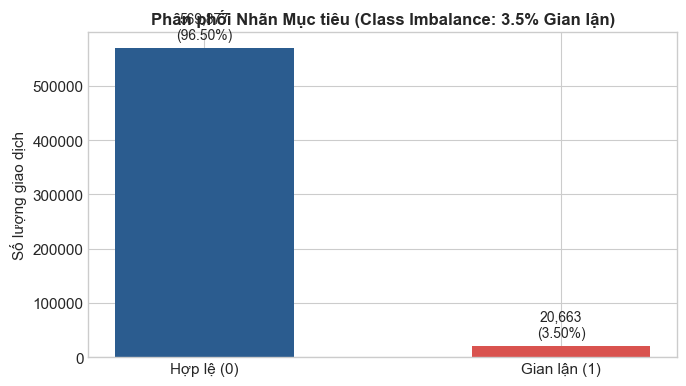

In [3]:
target_counts = df_tx['isFraud'].value_counts().to_pandas()
target_counts['TyLe_%'] = (target_counts['count'] / len(df_tx)) * 100
target_counts['Nhan'] = target_counts['isFraud'].map({0: 'Hợp lệ (Legit)', 1: 'Gian lận (Fraud)'})
print("Thống kê chi tiết nhãn mục tiêu:")
print(target_counts[['Nhan', 'count', 'TyLe_%']])

# Truc quan hoa
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(['Hợp lệ (0)', 'Gian lận (1)'], target_counts['count'], color=['#2b5c8f', '#d9534f'], width=0.5)
ax.set_title('Phân phối Nhãn Mục tiêu (Class Imbalance: 3.5% Gian lận)', fontsize=12, fontweight='bold')
ax.set_ylabel('Số lượng giao dịch')
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 10000, f"{yval:,}\n({yval/len(df_tx)*100:.2f}%)", ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'target_distribution.png'), dpi=150)
plt.show()


### 4. Phân tích Số Tiền Giao Dịch (Transaction Amount)
So sánh số tiền giao dịch (`TransactionAmt`) giữa giao dịch hợp lệ và giao dịch gian lận. Kẻ gian có xu hướng quẹt số tiền như thế nào?


So sánh thống kê số tiền thanh toán (USD):
       Nhan   GiaTri_TB  GiaTri_TrungVi  PhanVi_75  PhanVi_95  GiaTri_Max
0    Hợp lệ  134.511665            68.5      120.0      435.0   31937.391
1  Gian lận  149.244779            75.0      161.0      500.0    5191.000


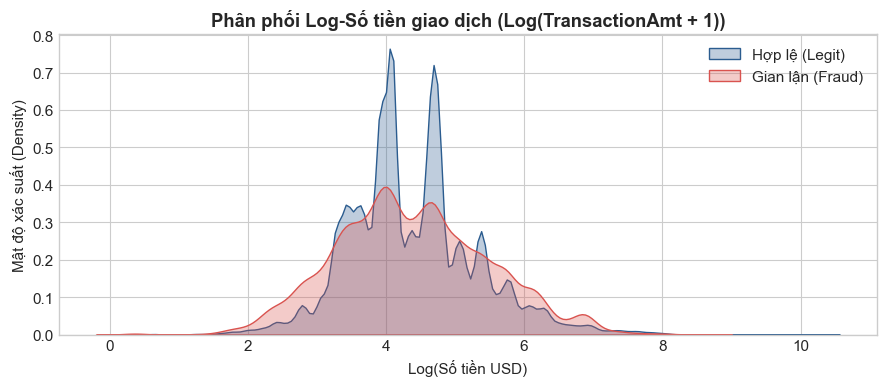

In [4]:
amt_stats = df_tx.group_by('isFraud').agg([
    pl.col('TransactionAmt').mean().alias('GiaTri_TB'),
    pl.col('TransactionAmt').median().alias('GiaTri_TrungVi'),
    pl.col('TransactionAmt').quantile(0.75).alias('PhanVi_75'),
    pl.col('TransactionAmt').quantile(0.95).alias('PhanVi_95'),
    pl.col('TransactionAmt').max().alias('GiaTri_Max')
]).to_pandas()
amt_stats['Nhan'] = amt_stats['isFraud'].map({0: 'Hợp lệ', 1: 'Gian lận'})
print("So sánh thống kê số tiền thanh toán (USD):")
print(amt_stats[['Nhan', 'GiaTri_TB', 'GiaTri_TrungVi', 'PhanVi_75', 'PhanVi_95', 'GiaTri_Max']])

# Ve bieu do phan phoi log so tien
legit_amt = np.log1p(df_tx.filter(pl.col('isFraud') == 0)['TransactionAmt'].to_numpy())
fraud_amt = np.log1p(df_tx.filter(pl.col('isFraud') == 1)['TransactionAmt'].to_numpy())

plt.figure(figsize=(9, 4))
sns.kdeplot(legit_amt, label='Hợp lệ (Legit)', color='#2b5c8f', fill=True, alpha=0.3)
sns.kdeplot(fraud_amt, label='Gian lận (Fraud)', color='#d9534f', fill=True, alpha=0.3)
plt.title('Phân phối Log-Số tiền giao dịch (Log(TransactionAmt + 1))', fontweight='bold')
plt.xlabel('Log(Số tiền USD)')
plt.ylabel('Mật độ xác suất (Density)')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'transaction_amt_density.png'), dpi=150)
plt.show()


### 5. Phân tích Trôi dạt Khái niệm theo Trục Thời gian (Concept Drift Analysis)
Cột `TransactionDT` là số giây tính từ mốc thời gian ban đầu. Chúng ta quy đổi thành Ngày (`Day = TransactionDT / 86400`) và khảo sát tỷ lệ gian lận thay đổi như thế nào theo thời gian.


Thống kê gian lận theo tuần (Concept Drift qua các tuần):
   Week  TongGiaoDich  SoGianLan  TyLeGianLan_%
0     0         23810        668       2.805544
1     1         27803        727       2.614826
2     2         34470        879       2.550044
3     3         37251        690       1.852299
4     4         24041        919       3.822636
5     5         21868        838       3.832083
6     6         20392        787       3.859357
7     7         20025        825       4.119850
8     8         20246        922       4.553986
9     9         23596       1014       4.297339


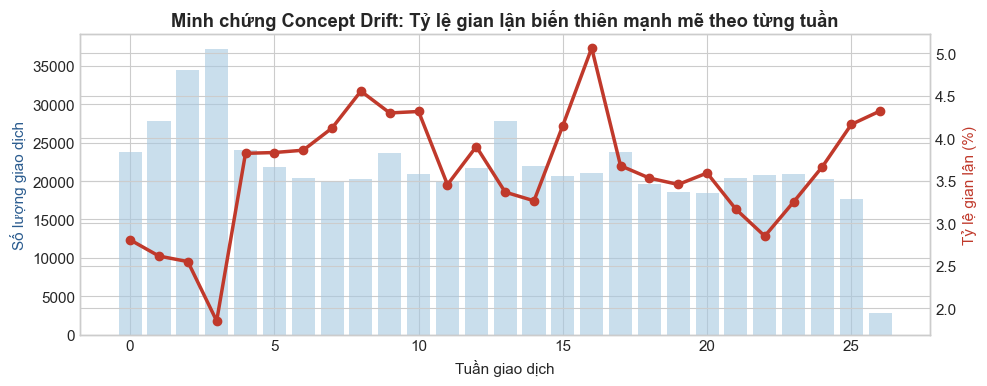

In [5]:
# Tao cot ngay va tuan
df_time = df_tx.select([
    (pl.col('TransactionDT') / 86400).cast(pl.Int32).alias('Day'),
    ((pl.col('TransactionDT') / 86400) / 7).cast(pl.Int32).alias('Week'),
    ((pl.col('TransactionDT') % 86400) / 3600).cast(pl.Int32).alias('HourOfDay'),
    pl.col('isFraud')
])

weekly_fraud = df_time.group_by('Week').agg([
    pl.len().alias('TongGiaoDich'),
    pl.col('isFraud').sum().alias('SoGianLan'),
    (pl.col('isFraud').mean() * 100).alias('TyLeGianLan_%')
]).sort('Week').to_pandas()

print("Thống kê gian lận theo tuần (Concept Drift qua các tuần):")
print(weekly_fraud.head(10))

fig, ax1 = plt.subplots(figsize=(10, 4))
ax2 = ax1.twinx()
ax1.bar(weekly_fraud['Week'], weekly_fraud['TongGiaoDich'], color='#a6c8e0', alpha=0.6, label='Lưu lượng giao dịch')
ax2.plot(weekly_fraud['Week'], weekly_fraud['TyLeGianLan_%'], color='#c0392b', marker='o', linewidth=2.5, label='Tỷ lệ gian lận (%)')
ax1.set_xlabel('Tuần giao dịch')
ax1.set_ylabel('Số lượng giao dịch', color='#2b5c8f')
ax2.set_ylabel('Tỷ lệ gian lận (%)', color='#c0392b')
plt.title('Minh chứng Concept Drift: Tỷ lệ gian lận biến thiên mạnh mẽ theo từng tuần', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'concept_drift_weekly.png'), dpi=150)
plt.show()


### 6. Giải mã các Nhóm Cột Bí ẩn (C, D, M, ProductCD)
Khám phá ý nghĩa thực tế của mã sản phẩm `ProductCD`, trường đếm `C1-C14`, khoảng cách ngày `D1` và trường so khớp `M1-M9`.


In [6]:
# Ty le gian lan theo ma san pham ProductCD
prod_fraud = df_tx.group_by('ProductCD').agg([
    pl.len().alias('SoLuong'),
    (pl.col('isFraud').mean() * 100).alias('TyLeGianLan_%')
]).sort('TyLeGianLan_%', descending=True).to_pandas()
print("Tỷ lệ rủi ro theo Mã sản phẩm (ProductCD):")
print(prod_fraud)

# Phan tich truong dem C1 va khoang cach D1
cd_sample = df_tx.select(['isFraud', 'C1', 'C2', 'D1', 'D2']).to_pandas()
print("\nThống kê mô tả các trường C1, C2, D1 (Mean theo từng nhóm):")
print(cd_sample.groupby('isFraud').mean())


Tỷ lệ rủi ro theo Mã sản phẩm (ProductCD):
  ProductCD  SoLuong  TyLeGianLan_%
0         C    68519      11.687269
1         S    11628       5.899553
2         H    33024       4.766231
3         R    37699       3.782594
4         W   439670       2.039939



Thống kê mô tả các trường C1, C2, D1 (Mean theo từng nhóm):
                C1         C2         D1          D2
isFraud                                             
0        13.314952  14.173283  96.364705  171.956223
1        35.535740  45.509413  38.711306   77.774206


### 7. Hiện thực hóa Kỹ nghệ Định danh Khách hàng "Magic UID"
Vì không có cột `userID`, chúng ta sử dụng công thức ghép khóa tổng hợp kinh điển:
$$\text{Card\_ID} = \text{card1} \_ \text{card2} \_ \text{card3} \_ \text{card4} \_ \text{card6} \_ \text{addr1}$$
$$\text{Card\_Birth\_Day} = \text{Day} - \text{D1}$$
$$\text{Client\_UID} = \text{Card\_ID} \_ \text{Card\_Birth\_Day}$$


In [7]:
# Tao ma dinh danh Magic UID bang Polars
df_uid = df_tx.select([
    pl.col('TransactionID'),
    pl.col('isFraud'),
    (pl.col('TransactionDT') / 86400).alias('Day'),
    pl.col('D1'),
    (
        pl.col('card1').cast(pl.String) + '_' + 
        pl.col('card2').cast(pl.String).fill_null('0') + '_' +
        pl.col('card3').cast(pl.String).fill_null('0') + '_' +
        pl.col('card4').cast(pl.String).fill_null('na') + '_' +
        pl.col('card6').cast(pl.String).fill_null('na') + '_' +
        pl.col('addr1').cast(pl.String).fill_null('0')
    ).alias('Card_ID')
])

# Tinh ngay sinh cua the (Card Birth Day)
df_uid = df_uid.with_columns([
    ((pl.col('Day') - pl.col('D1').fill_null(0.0)).round(1).cast(pl.String)).alias('Birth_Day')
])

df_uid = df_uid.with_columns([
    (pl.col('Card_ID') + '_' + pl.col('Birth_Day')).alias('Client_UID')
])

total_tx = len(df_uid)
unique_cards = df_uid['Card_ID'].n_unique()
unique_clients = df_uid['Client_UID'].n_unique()

print(f"-> Tổng số giao dịch trong hệ thống:        {total_tx:,}")
print(f"-> Số lượng thẻ vật lý duy nhất (Card_ID):   {unique_cards:,}")
print(f"-> Số lượng khách hàng duy nhất (Client_UID): {unique_clients:,}")
print(f"-> Tỷ lệ gom cụm: Trung bình mỗi khách hàng thực hiện {total_tx / unique_clients:.2f} giao dịch.")


-> Tổng số giao dịch trong hệ thống:        590,540
-> Số lượng thẻ vật lý duy nhất (Card_ID):   41,888
-> Số lượng khách hàng duy nhất (Client_UID): 387,059
-> Tỷ lệ gom cụm: Trung bình mỗi khách hàng thực hiện 1.53 giao dịch.


### 8. Tối ưu hóa Lưu trữ: Chuyển đổi Dữ liệu sang Định dạng Apache Parquet
Để phục vụ huấn luyện mô hình máy học và giảm thiểu tài nguyên bộ nhớ cho hệ thống, chúng ta chuyển đổi toàn bộ file CSV nặng sang chuẩn nén **Parquet**.


In [8]:
parquet_tx = os.path.join(PROCESSED_DATA_DIR, 'train_transaction.parquet')
parquet_id = os.path.join(PROCESSED_DATA_DIR, 'train_identity.parquet')

t0 = time.time()
df_tx.write_parquet(parquet_tx, compression='zstd')
df_id.write_parquet(parquet_id, compression='zstd')
save_time = time.time() - t0

csv_size_mb = os.path.getsize(tx_path) / (1024 * 1024)
parquet_size_mb = os.path.getsize(parquet_tx) / (1024 * 1024)

print(f"-> Ghi Parquet thành công trong: {save_time:.2f} giây!")
print(f"-> Kích thước CSV ban đầu:    {csv_size_mb:.1f} MB")
print(f"-> Kích thước Parquet nén:    {parquet_size_mb:.1f} MB (Tiết kiệm {(1 - parquet_size_mb/csv_size_mb)*100:.1f}% dung lượng đĩa!)")


-> Ghi Parquet thành công trong: 2.71 giây!
-> Kích thước CSV ban đầu:    651.7 MB
-> Kích thước Parquet nén:    69.6 MB (Tiết kiệm 89.3% dung lượng đĩa!)


### 9. Kết Luận & Định Hướng Xây Dựng Khung Conformal Prediction
1. **Dữ liệu thực tế có độ mất cân bằng nghiêm trọng:** Chỉ $3.5\%$ là giao dịch gian lận. Việc dùng ngưỡng cố định $0.5$ của các mô hình thông thường sẽ hoàn toàn thất bại. Cần áp dụng **Hàm mất mát nhạy cảm chi phí (Cost-Sensitive Matrix)**.
2. **Concept Drift rõ rệt theo tuần:** Tỷ lệ gian lận biến thiên liên tục, đòi hỏi phương pháp **Dự báo Conformal (Conformal Prediction)** với khả năng bảo chứng vùng bất định để chuyển các ca nghi ngờ sang xác thực 2 bước (Step-up OTP).
3. **Kỹ nghệ Magic UID thành công:** Đã giải quyết triệt để bài toán thiếu `userID`, cho phép phân cụm và theo dõi lịch sử khách hàng trên toàn bộ vòng đời thẻ.
